In [1]:
!pip -q install yfinance

#  Limitations

This project has several important limitations.

1. The Black–Scholes model assumes constant volatility, constant interest rates, continuous trading, frictionless markets, and European-style exercise. Real markets exhibit changing volatility, transaction costs, bid–ask spreads, liquidity constraints, and volatility smiles or skews.

2. SPY options are generally American-style options, while the Black–Scholes implementation in this notebook prices European-style options. The model is therefore used as an analytical approximation and benchmark rather than an exact SPY-option valuation model.

3. Historical volatility is backward-looking and may not equal the implied volatility observed in option prices. A more advanced project could retrieve option-chain data and compare historical volatility with implied volatility.



In [2]:
import os
import sys
import math
import warnings
from pathlib import Path
from datetime import date

import numpy as np
import pandas as pd
import yfinance as yf

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import norm
from scipy.optimize import minimize

warnings.filterwarnings("ignore")

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_theme(style="whitegrid", palette="deep")

np.random.seed(42)

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print("Python version:", sys.version.split()[0])
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("yfinance version:", yf.__version__)

Python version: 3.13.16
NumPy version: 2.1.3
Pandas version: 2.2.3
yfinance version: 0.2.66


In [3]:

from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [4]:
PROJECT_DIR = "/content/drive/MyDrive/quant-risk-derivatives-engine"

DATA_RAW_DIR = f"{PROJECT_DIR}/data/raw"
DATA_PROCESSED_DIR = f"{PROJECT_DIR}/data/processed"
FIGURES_DIR = f"{PROJECT_DIR}/figures"
OUTPUTS_DIR = f"{PROJECT_DIR}/outputs"

for folder in [DATA_RAW_DIR, DATA_PROCESSED_DIR, FIGURES_DIR, OUTPUTS_DIR]:
    os.makedirs(folder, exist_ok=True)

print("Project folders are ready.")
print("Project location:", PROJECT_DIR)

Project folders are ready.
Project location: /content/drive/MyDrive/quant-risk-derivatives-engine


In [5]:
# ============================================================
# : DEFINE DATA PARAMETERS
# ============================================================
# We use a long sample beginning in 2015 so that later sections
# can examine normal periods, high-volatility periods, and
# different market regimes.
#
# END_DATE is set to today's date automatically when the
# notebook is run. This makes the project current, but it also
# means results can differ if you rerun the notebook later.
# ============================================================

SPY_TICKER = "SPY"

START_DATE = "2015-01-01"
END_DATE = pd.Timestamp.today().strftime("%Y-%m-%d")

print(f"Ticker:     {SPY_TICKER}")
print(f"Start date: {START_DATE}")
print(f"End date:   {END_DATE}")

Ticker:     SPY
Start date: 2015-01-01
End date:   2026-10-21


Why start in 2015?
A sample beginning in 2015 provides enough data to later examine:

Long-run volatility

The 2020 COVID-19 market shock

The 2022 interest-rate shock

More recent market conditions






In [6]:
# ============================================================
# DOWNLOAD SPY DAILY PRICE DATA
# ============================================================
# auto_adjust=True adjusts historical prices for stock splits
# and distributions. We use adjusted prices because they are
# more appropriate for calculating historical investment returns.
#
# interval="1d" requests daily data.
# progress=False keeps the notebook output clean.
# ============================================================

spy_raw = yf.download(
    tickers=SPY_TICKER,
    start=START_DATE,
    end=END_DATE,
    interval="1d",
    auto_adjust=True,
    progress=False
)

# Display the first five rows to confirm the download worked.
spy_raw.head()

Price,Close,High,Low,Open,Volume
Ticker,SPY,SPY,SPY,SPY,SPY
Date,,,,,
2015-01-02,169.2675,170.4623,168.2375,170.0503,121465900
2015-01-05,166.2106,168.3941,165.9057,168.2293,169632600
2015-01-06,164.6451,167.0346,163.8541,166.5155,209151400
2015-01-07,166.6967,167.0346,165.5185,165.9634,125346700
2015-01-08,169.6548,169.8690,168.0810,168.0975,147217800


In [7]:
# ============================================================
# CLEAN AND STANDARDIZE SPY DATA
# ============================================================
# We retain only the adjusted closing-price series because this
# is the main input for return and volatility calculations.
#
# Some versions of yfinance return columns in a MultiIndex structure, even for one ticker. The code below handles both possible formats safely.
# ============================================================

# If the returned columns are a MultiIndex, extract the SPY  closing-price series. Otherwise, use the standard Close column.
if isinstance(spy_raw.columns, pd.MultiIndex):
    spy_prices = spy_raw["Close"][SPY_TICKER].to_frame(name="SPY_Adjusted_Close")
else:
    spy_prices = spy_raw[["Close"]].rename(columns={"Close": "SPY_Adjusted_Close"})

# Remove any rows with missing values.
spy_prices = spy_prices.dropna()

# Ensure the Date index is stored as a datetime index.
spy_prices.index = pd.to_datetime(spy_prices.index)

# Sort by date in ascending order as a safety check.
spy_prices = spy_prices.sort_index()

# Display summary information.
print(f"Number of observations: {len(spy_prices):,}")
print(f"First available date:   {spy_prices.index.min().date()}")
print(f"Last available date:    {spy_prices.index.max().date()}")

spy_prices.head()

Number of observations: 2,967
First available date:   2015-01-02
Last available date:    2026-10-20


,SPY_Adjusted_Close
Date,
2015-01-02,169.2675
2015-01-05,166.2106
2015-01-06,164.6451
2015-01-07,166.6967
2015-01-08,169.6548


In [8]:
# ============================================================
# DATA-QUALITY CHECKS
# ============================================================
# Before doing financial calculations, check:
# 1. Missing values
# 2. Duplicate dates
# 3. Non-positive prices
# 4. Overall descriptive statistics
# ============================================================

print("Missing values:")
print(spy_prices.isna().sum())

print("\nDuplicate dates:")
print(spy_prices.index.duplicated().sum())

print("\nNon-positive prices:")
print((spy_prices["SPY_Adjusted_Close"] <= 0).sum())

print("\nDescriptive statistics:")
display(spy_prices.describe())

Missing values:
SPY_Adjusted_Close    0
dtype: int64

Duplicate dates:
0

Non-positive prices:
0

Descriptive statistics:


,SPY_Adjusted_Close
count,"2,967.0000"
mean,361.5461
std,166.6153
min,153.7798
25%,225.2766
50%,332.6035
75%,439.0803
max,779.0900


In [9]:
# ============================================================
# SAVE RAW SPY PRICE DATA
# ============================================================
# Saving the downloaded data protects your work if:
# - the Colab session ends,
# - the data source changes,
# - you want to reproduce the same analysis later.
# ============================================================

spy_raw_file = f"{DATA_RAW_DIR}/spy_daily_adjusted_prices.csv"

spy_prices.to_csv(spy_raw_file)

print(f"SPY price data saved to:\n{spy_raw_file}")

SPY price data saved to:
/content/drive/MyDrive/quant-risk-derivatives-engine/data/raw/spy_daily_adjusted_prices.csv


In [10]:
# ============================================================
# CALCULATE DAILY SPY RETURNS
# ============================================================
# Simple return:
#     R_t = (P_t / P_(t-1)) - 1
#
# Log return:
#     r_t = ln(P_t / P_(t-1))
#
# The first row has no prior day's price, so it becomes missing.
# We remove that first missing-return observation with dropna().
# ============================================================

spy_data = spy_prices.copy()

spy_data["Simple_Return"] = spy_data["SPY_Adjusted_Close"].pct_change()

spy_data["Log_Return"] = np.log(
    spy_data["SPY_Adjusted_Close"]
    / spy_data["SPY_Adjusted_Close"].shift(1)
)

spy_data = spy_data.dropna()

spy_data.head()

,SPY_Adjusted_Close,Simple_Return,Log_Return
Date,,,
2015-01-05,166.2106,-0.0181,-0.0182
2015-01-06,164.6451,-0.0094,-0.0095
2015-01-07,166.6967,0.0125,0.0124
2015-01-08,169.6548,0.0177,0.0176
2015-01-09,168.2952,-0.0080,-0.0080


In [11]:
# ============================================================
# SPY RETURN SUMMARY STATISTICS
# ============================================================
# We annualize return and volatility using 252 trading days,
# which is the standard approximation for US equity markets.
# ============================================================

TRADING_DAYS = 252

mean_daily_return = spy_data["Simple_Return"].mean()
daily_volatility = spy_data["Simple_Return"].std()

annualized_return = (1 + mean_daily_return) ** TRADING_DAYS - 1
annualized_volatility = daily_volatility * np.sqrt(TRADING_DAYS)

summary_statistics = pd.DataFrame({
    "Metric": [
        "Mean daily simple return",
        "Daily volatility",
        "Annualized return (approx.)",
        "Annualized volatility"
    ],
    "Value": [
        mean_daily_return,
        daily_volatility,
        annualized_return,
        annualized_volatility
    ]
})

# Format the values as percentages for easy reading.
summary_statistics["Value"] = summary_statistics["Value"].map(lambda x: f"{x:.2%}")

summary_statistics

,Metric,Value
0,Mean daily simple return,0.06%
1,Daily volatility,1.10%
2,Annualized return (approx.),15.48%
3,Annualized volatility,17.50%


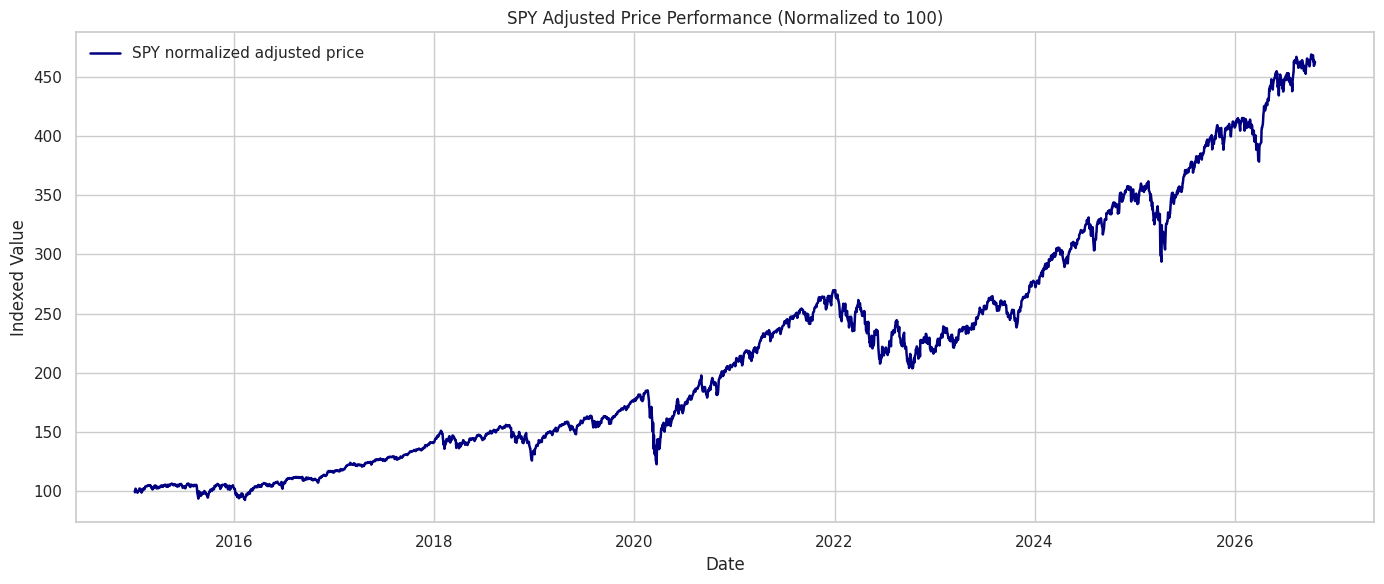

In [12]:
# ============================================================
# NORMALIZED SPY PRICE CHART
# ============================================================
# We convert the first price to 100, then show how the value
# would have changed over time relative to that starting point.
#
# This does NOT mean SPY was priced at $100. It simply creates
# an index where the first observation equals 100.
# ============================================================

spy_data["Normalized_Price"] = (
    spy_data["SPY_Adjusted_Close"]
    / spy_data["SPY_Adjusted_Close"].iloc[0]
) * 100

plt.figure(figsize=(14, 6))

plt.plot(
    spy_data.index,
    spy_data["Normalized_Price"],
    color="navy",
    linewidth=1.8,
    label="SPY normalized adjusted price"
)

plt.title("SPY Adjusted Price Performance (Normalized to 100)")
plt.xlabel("Date")
plt.ylabel("Indexed Value")
plt.legend()

plt.tight_layout()

plt.savefig(
    f"{FIGURES_DIR}/04_spy_normalized_price.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

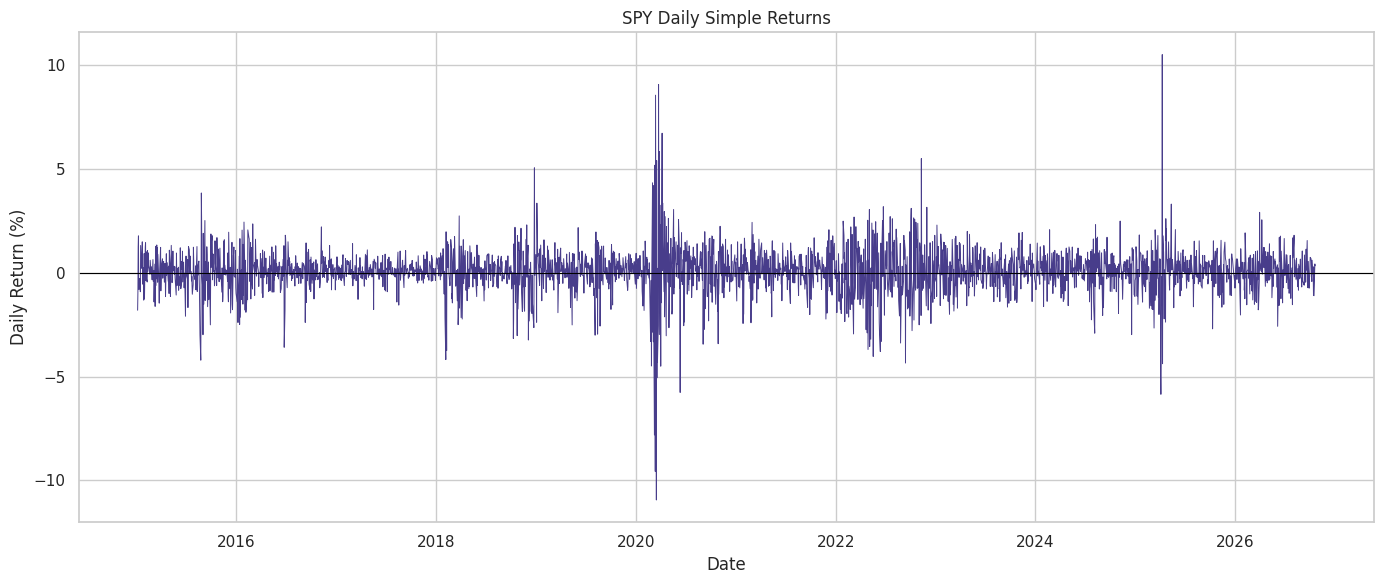

In [13]:
# ============================================================
# DAILY SPY RETURNS
# ============================================================
# This plot shows day-to-day percentage changes rather than
# price levels. Large positive or negative movements are useful
# for identifying periods of elevated market risk.
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    spy_data.index,
    spy_data["Simple_Return"] * 100,
    color="darkslateblue",
    linewidth=0.7
)

plt.axhline(0, color="black", linewidth=0.8)

plt.title("SPY Daily Simple Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")

plt.tight_layout()

plt.savefig(
    f"{FIGURES_DIR}/05_spy_daily_returns.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
# ============================================================
# DOWNLOAD FRED 3-MONTH TREASURY YIELD (DGS3MO)
# ============================================================
# DGS3MO is the 3-month US Treasury constant-maturity yield.
# FRED reports the series in PERCENT, not decimal form.
#
# We use a direct CSV link, so no FRED API key is required.
# ============================================================

fred_url = (
    "https://fred.stlouisfed.org/graph/fredgraph.csv"
    "?id=DGS3MO"
)

risk_free_data = pd.read_csv(fred_url)

risk_free_data.head()

,observation_date,DGS3MO
0,1981-09-01,17.0100
1,1981-09-02,16.6500
2,1981-09-03,16.9600
3,1981-09-04,16.6400
4,1981-09-07,NaN


In [15]:
# ============================================================
# CLEAN THE RISK-FREE RATE SERIES
# ============================================================
# FRED may use "." to represent missing values.
# We convert values to numeric, remove missing observations,
# and convert percentages to decimals.
# ============================================================

risk_free_data["observation_date"] = pd.to_datetime(
    risk_free_data["observation_date"]
)

risk_free_data["DGS3MO"] = pd.to_numeric(
    risk_free_data["DGS3MO"],
    errors="coerce"
)

risk_free_data = risk_free_data.dropna()

risk_free_data = risk_free_data.rename(
    columns={
        "observation_date": "Date",
        "DGS3MO": "Three_Month_Treasury_Yield_Percent"
    }
)

# Convert percentage values to decimal values.
# Example: 4.25 becomes 0.0425.
risk_free_data["Risk_Free_Rate"] = (
    risk_free_data["Three_Month_Treasury_Yield_Percent"] / 100
)

# Set the date as the table index.
risk_free_data = risk_free_data.set_index("Date").sort_index()

risk_free_data.tail()

,Three_Month_Treasury_Yield_Percent,Risk_Free_Rate
Date,,
2026-10-13,4.2600,0.0426
2026-10-14,4.2800,0.0428
2026-10-15,4.2800,0.0428
2026-10-16,4.2600,0.0426
2026-10-19,4.2700,0.0427


In [16]:
# ============================================================
# LATEST AVAILABLE RISK-FREE RATE
# ============================================================
# FRED may not contain data for the exact date on which you
# run the notebook, such as a weekend or public holiday.
# Therefore, we use the last available observation.
# ============================================================

latest_rate_date = risk_free_data.index[-1]
latest_risk_free_rate = risk_free_data["Risk_Free_Rate"].iloc[-1]

print(f"Latest available DGS3MO date: {latest_rate_date.date()}")
print(f"3-month Treasury yield:        {latest_risk_free_rate:.2%}")

Latest available DGS3MO date: 2026-10-19
3-month Treasury yield:        4.27%


In [17]:
r= latest_risk_free_rate

In [18]:
# ============================================================
# SAVE RISK-FREE RATE DATA
# ============================================================

risk_free_file = f"{DATA_RAW_DIR}/fred_dgs3mo_risk_free_rate.csv"

risk_free_data.to_csv(risk_free_file)

print(f"Risk-free-rate data saved to:\n{risk_free_file}")

Risk-free-rate data saved to:
/content/drive/MyDrive/quant-risk-derivatives-engine/data/raw/fred_dgs3mo_risk_free_rate.csv


In [19]:
# ============================================================
# REAL MARKET DATA SUMMARY
# ============================================================
# This summary table records the current inputs that will later
# feed into the Black-Scholes model.
#
# Historical volatility is not added yet. It will be estimated
# properly in Section 7.
# ============================================================

latest_spy_date = spy_data.index[-1]
latest_spy_price = spy_data["SPY_Adjusted_Close"].iloc[-1]

market_data_summary = pd.DataFrame({
    "Input": [
        "Underlying asset",
        "Latest SPY observation date",
        "Latest SPY adjusted closing price",
        "Risk-free rate proxy",
        "Risk-free-rate observation date",
        "Risk-free rate",
        "Historical sample start date",
        "Historical sample end date"
    ],
    "Value": [
        "SPY",
        latest_spy_date.strftime("%Y-%m-%d"),
        f"${latest_spy_price:,.2f}",
        "FRED DGS3MO (3-month Treasury yield)",
        latest_rate_date.strftime("%Y-%m-%d"),
        f"{latest_risk_free_rate:.2%}",
        spy_data.index.min().strftime("%Y-%m-%d"),
        spy_data.index.max().strftime("%Y-%m-%d")
    ]
})

market_data_summary

,Input,Value
0,Underlying asset,SPY
1,Latest SPY observation date,2026-10-20
2,Latest SPY adjusted closing price,$769.05
3,Risk-free rate proxy,FRED DGS3MO (3-month Treasury yield)
4,Risk-free-rate observation date,2026-10-19
5,Risk-free rate,4.27%
6,Historical sample start date,2015-01-05
7,Historical sample end date,2026-10-20


In [20]:
# ============================================================
# SAVE PROCESSED DATA AND SUMMARY
# ============================================================

spy_processed_file = f"{DATA_PROCESSED_DIR}/spy_daily_returns.csv"
summary_file = f"{OUTPUTS_DIR}/section_06_market_data_summary.csv"

spy_data.to_csv(spy_processed_file)
market_data_summary.to_csv(summary_file, index=False)

print("Saved processed SPY data and market-data summary.")

Saved processed SPY data and market-data summary.


In [21]:
# ============================================================
#  HISTORICAL AND ROLLING VOLATILITY
# ============================================================
#  use logarithmic returns for volatility analysis because log returns are additive over time and commonly used in
# financial modeling.
#
# 252 is the conventional approximation for annual trading days.
# ============================================================

TRADING_DAYS = 252

# Create a separate DataFrame so we do not accidentally modify
# the original SPY data from
volatility_data = spy_data.copy()

# Rolling historical volatility:
# rolling standard deviation of daily log returns × sqrt(252)
volatility_data["Vol_30D"] = (
    volatility_data["Log_Return"]
    .rolling(window=30)
    .std()
    * np.sqrt(TRADING_DAYS)
)

volatility_data["Vol_60D"] = (
    volatility_data["Log_Return"]
    .rolling(window=60)
    .std()
    * np.sqrt(TRADING_DAYS)
)

volatility_data["Vol_252D"] = (
    volatility_data["Log_Return"]
    .rolling(window=252)
    .std()
    * np.sqrt(TRADING_DAYS)
)

# EWMA volatility:
# span=60 places more weight on recent observations.
# This makes the estimate react faster to market changes.
volatility_data["EWMA_Vol_60D"] = (
    volatility_data["Log_Return"]
    .ewm(span=60, adjust=False)
    .std()
    * np.sqrt(TRADING_DAYS)
)

volatility_data.tail()

,SPY_Adjusted_Close,Simple_Return,Log_Return,Normalized_Price,Vol_30D,Vol_60D,Vol_252D,EWMA_Vol_60D
Date,,,,,,,,
2026-10-14,769.6000,-0.0108,-0.0109,463.0271,0.1013,0.1097,0.1267,0.1064
2026-10-15,771.7900,0.0028,0.0028,464.3447,0.1008,0.1097,0.1267,0.1049
2026-10-16,763.2500,-0.0111,-0.0111,459.2067,0.1015,0.1091,0.1272,0.1083
2026-10-19,766.4800,0.0042,0.0042,461.1500,0.1018,0.1094,0.1270,0.1072
2026-10-20,769.0500,0.0034,0.0033,462.6962,0.1009,0.1095,0.1270,0.1058


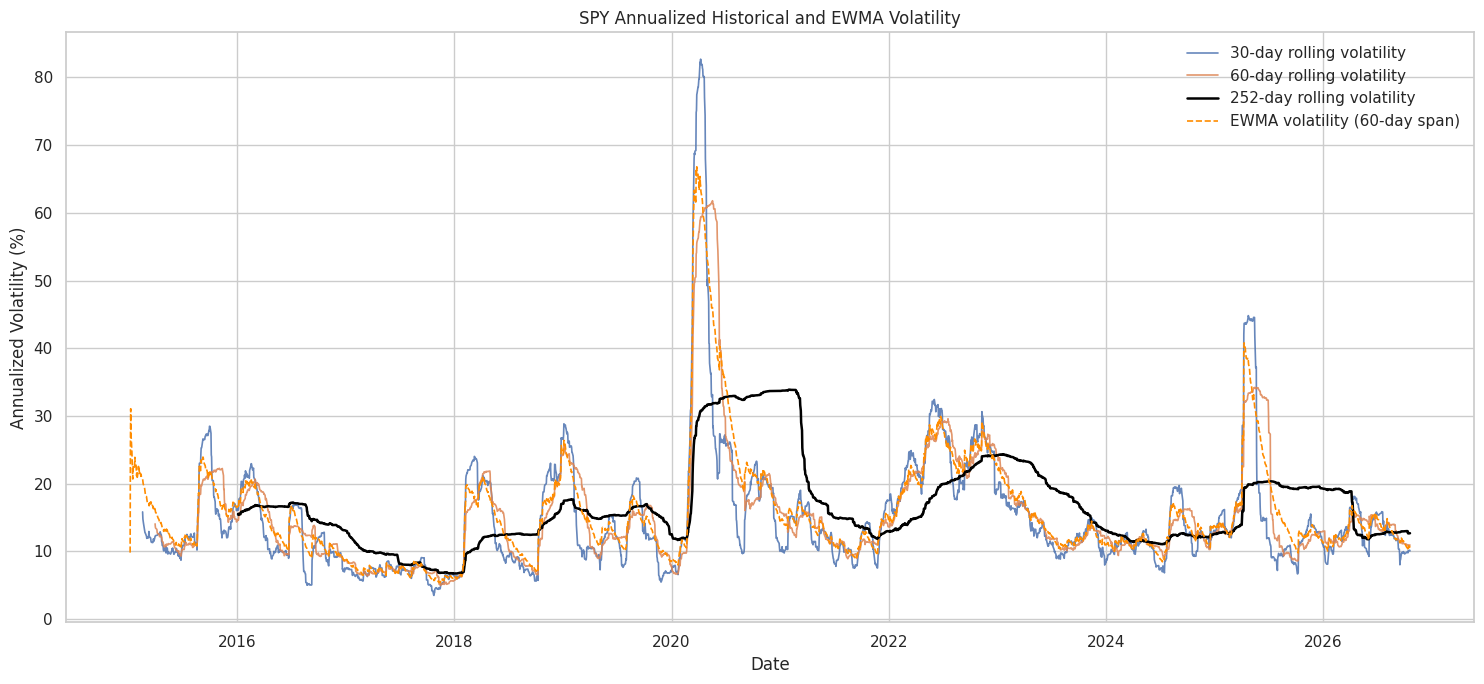

In [22]:
# ============================================================
# PLOT SPY ROLLING VOLATILITY
# ============================================================

plt.figure(figsize=(15, 7))

plt.plot(
    volatility_data.index,
    volatility_data["Vol_30D"] * 100,
    label="30-day rolling volatility",
    linewidth=1.2,
    alpha=0.85
)

plt.plot(
    volatility_data.index,
    volatility_data["Vol_60D"] * 100,
    label="60-day rolling volatility",
    linewidth=1.2,
    alpha=0.85
)

plt.plot(
    volatility_data.index,
    volatility_data["Vol_252D"] * 100,
    label="252-day rolling volatility",
    linewidth=1.8,
    color="black"
)

plt.plot(
    volatility_data.index,
    volatility_data["EWMA_Vol_60D"] * 100,
    label="EWMA volatility (60-day span)",
    linewidth=1.2,
    linestyle="--",
    color="darkorange"
)

plt.title("SPY Annualized Historical and EWMA Volatility")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility (%)")
plt.legend()
plt.tight_layout()

plt.savefig(
    f"{FIGURES_DIR}/06_spy_rolling_volatility.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
# ============================================================
# SELECT A VOLATILITY INPUT FOR LATER OPTION PRICING
# ============================================================
# We use the latest available 60-day historical volatility as
# the baseline volatility input for Black-Scholes and Monte Carlo.
#
# This is a modeling choice, not a universal truth. Later, you can compare results using 30-day, 60-day, 252-day, and
# EWMA volatility estimates.
# ============================================================

latest_volatility_date = volatility_data.dropna(subset=["Vol_60D"]).index[-1]

sigma_30d = volatility_data.loc[latest_volatility_date, "Vol_30D"]
sigma_60d = volatility_data.loc[latest_volatility_date, "Vol_60D"]
sigma_252d = volatility_data.loc[latest_volatility_date, "Vol_252D"]
sigma_ewma = volatility_data.loc[latest_volatility_date, "EWMA_Vol_60D"]

# Select 60-day rolling volatility as baseline.
market_sigma = sigma_60d

volatility_summary = pd.DataFrame({
    "Volatility Measure": [
        "30-day rolling volatility",
        "60-day rolling volatility",
        "252-day rolling volatility",
        "EWMA volatility (60-day span)"
    ],
    "Annualized Volatility": [
        sigma_30d,
        sigma_60d,
        sigma_252d,
        sigma_ewma
    ]
})

volatility_summary["Annualized Volatility"] = (
    volatility_summary["Annualized Volatility"]
    .map(lambda x: f"{x:.2%}")
)

print(f"Latest volatility observation date: {latest_volatility_date.date()}")
print(f"Selected 60-day volatility:         {market_sigma:.2%}")

volatility_summary

Latest volatility observation date: 2026-10-20
Selected 60-day volatility:         10.95%


,Volatility Measure,Annualized Volatility
0,30-day rolling volatility,10.09%
1,60-day rolling volatility,10.95%
2,252-day rolling volatility,12.70%
3,EWMA volatility (60-day span),10.58%


In [24]:
sigma = market_sigma

In [25]:
print(sigma)

0.10949205197504959


In [26]:
# ============================================================
# SAVE VOLATILITY OUTPUTS
# ============================================================

volatility_data.to_csv(
    f"{DATA_PROCESSED_DIR}/spy_volatility_estimates.csv"
)

volatility_summary.to_csv(
    f"{OUTPUTS_DIR}/section_07_volatility_summary.csv",
    index=False
)

print("Section 7 files saved successfully.")

Section 7 files saved successfully.


# The European Option Contract

The experiment studies a European call and put on SPY. A European option can be exercised only at expiration.

The contract assumptions are:

- **Spot price, \(S_0\):** latest available unadjusted SPY closing price.
- **Strike price, \(K\):** set equal to \(S_0\), creating an at-the-money example.
- **Time to expiration, \(T\):** 30 calendar days expressed as a fraction of a year.
- **Risk-free rate, \(r\):** latest available FRED 3-month Treasury yield, converted to decimal form.
- **Volatility, \(\sigma\):** latest available 60-day annualized historical volatility estimate.
- **Dividend yield, \(q\):** initially set to zero as a simplifying assumption.

The zero dividend-yield assumption is a known simplification because SPY distributes dividends. We will document it rather than imply it is a complete representation of SPY.

The chosen strike and maturity define a research scenario; they are not evidence of an actual listed option's current market quote.

#Pricing Black_scholes

In [27]:
S0 = float(spy_data["SPY_Adjusted_Close"].iloc[-1])

In [28]:
# ============================================================
# OPTION CONTRACT AND BASELINE MODEL INPUTS
# ============================================================

K = S0                 # At-the-money strike assumption
T = 30 / 365           # 30 calendar days, in years
q = 0.0                # Simplifying dividend-yield assumption

option_inputs = pd.DataFrame({
    "Parameter": [
        "Underlying",
        "Spot price (S0)",
        "Strike (K)",
        "Time to expiration (T)",
        "Risk-free rate (r)",
        "Annualized volatility (sigma)",
        "Dividend yield (q)"
    ],
    "Value": [
        SPY_TICKER,
        f"${S0:.2f}",
        f"${K:.2f}",
        f"{T:.6f} years",
        f"{r:.4%}",
        f"{sigma:.4%}",
        f"{q:.2%}"
    ]
})

display(option_inputs)

,Parameter,Value
0,Underlying,SPY
1,Spot price (S0),$769.05
2,Strike (K),$769.05
3,Time to expiration (T),0.082192 years
4,Risk-free rate (r),4.2700%
5,Annualized volatility (sigma),10.9492%
6,Dividend yield (q),0.00%


In [29]:
# ============================================================
# BLACK-SCHOLES PRICING FUNCTIONS
# ============================================================

def calculate_d1_d2(S0, K, T, r, sigma, q=0.0):
    """
    Calculate the intermediate d1 and d2 terms used by
    the Black-Scholes European option-pricing formulas.
    """

    # These checks prevent invalid logarithms and division by zero.
    if S0 <= 0:
        raise ValueError("Spot price S0 must be positive.")
    if K <= 0:
        raise ValueError("Strike price K must be positive.")
    if T <= 0:
        raise ValueError("Time to expiration T must be positive.")
    if sigma <= 0:
        raise ValueError("Volatility sigma must be positive.")

    d1 = (
        np.log(S0 / K)
        + (r - q + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    return d1, d2


def black_scholes_price(
    S0, K, T, r, sigma, option_type="call", q=0.0
):
    """
    Calculate a European call or put price using Black-Scholes.

    All rates and volatility must be expressed as decimals.
    Time to expiration must be expressed in years.
    """

    d1, d2 = calculate_d1_d2(S0, K, T, r, sigma, q)

    # Present-value factors for the underlying and strike.
    spot_discount = np.exp(-q * T)
    strike_discount = np.exp(-r * T)

    # Apply the relevant closed-form formula.
    if option_type.lower() == "call":
        price = (
            S0 * spot_discount * norm.cdf(d1)
            - K * strike_discount * norm.cdf(d2)
        )

    elif option_type.lower() == "put":
        price = (
            K * strike_discount * norm.cdf(-d2)
            - S0 * spot_discount * norm.cdf(-d1)
        )

    else:
        raise ValueError("option_type must be 'call' or 'put'.")

    return float(price)


# Calculate the two theoretical option prices.
call_bs = black_scholes_price(
    S0, K, T, r, sigma, option_type="call", q=q
)

put_bs = black_scholes_price(
    S0, K, T, r, sigma, option_type="put", q=q
)

print(f"Black-Scholes European call: ${call_bs:.4f}")
print(f"Black-Scholes European put:  ${put_bs:.4f}")

Black-Scholes European call: $11.0207
Black-Scholes European put:  $8.3264


# Monte Carlo Pricing

In [30]:
def monte_carlo_price(
    S0,
    K,
    T,
    r,
    sigma,
    option_type="call",
    q=0.0,
    n_simulations=100_000,
    seed=42
):
    """
    Estimate a European option price using Monte Carlo simulation.

    Returns the estimated price, standard error, confidence interval,
    and number of simulations.
    """

    # Check that the inputs are economically valid.
    if S0 <= 0 or K <= 0:
        raise ValueError("S0 and K must be positive.")

    if T <= 0:
        raise ValueError("T must be positive.")

    if sigma <= 0:
        raise ValueError("sigma must be positive.")

    if n_simulations < 2:
        raise ValueError("Use at least two simulations.")

    # A fixed seed makes the simulation reproducible.
    rng = np.random.default_rng(seed)

    # Generate independent standard normal random variables.
    Z = rng.standard_normal(n_simulations)

    # Simulate stock prices at option expiration.
    ST = S0 * np.exp(
        (r - q - 0.5 * sigma**2) * T
        + sigma * np.sqrt(T) * Z
    )

    # Calculate the option payoff in each simulation.
    if option_type.lower() == "call":
        payoff = np.maximum(ST - K, 0)

    elif option_type.lower() == "put":
        payoff = np.maximum(K - ST, 0)

    else:
        raise ValueError("option_type must be 'call' or 'put'.")

    # Discount each payoff to its present value.
    discounted_payoff = np.exp(-r * T) * payoff

    # Estimate the option price from the average discounted payoff.
    price_estimate = discounted_payoff.mean()

    # Estimate Monte Carlo sampling uncertainty.
    standard_error = (
        discounted_payoff.std(ddof=1) / np.sqrt(n_simulations)
    )

    # Construct an approximate 95% confidence interval.
    confidence_low = price_estimate - 1.96 * standard_error
    confidence_high = price_estimate + 1.96 * standard_error

    return {
        "price": float(price_estimate),
        "standard_error": float(standard_error),
        "confidence_low": float(confidence_low),
        "confidence_high": float(confidence_high),
        "n_simulations": n_simulations
    }


# Price a call and a put using Monte Carlo.
mc_call = monte_carlo_price(
    S0, K, T, r, sigma,
    option_type="call",
    q=q,
    n_simulations=100_000,
    seed=42
)

mc_put = monte_carlo_price(
    S0, K, T, r, sigma,
    option_type="put",
    q=q,
    n_simulations=100_000,
    seed=43
)

mc_results = pd.DataFrame(
    [
        {"Option": "Call", **mc_call},
        {"Option": "Put", **mc_put}
    ]
)

mc_results

,Option,price,standard_error,confidence_low,confidence_high,n_simulations
0,Call,10.9815,0.0484,10.8866,11.0765,100000
1,Put,8.3395,0.0407,8.2597,8.4192,100000


## Monte Carlo Validation against Black Scholes

In [31]:
def compare_mc_with_black_scholes(mc_result, bs_price):
    """Summarize Monte Carlo accuracy against a Black–Scholes benchmark."""

    return {
        "Black-Scholes Price": bs_price,
        "Monte Carlo Price": mc_result["price"],
        "Absolute Difference": abs(mc_result["price"] - bs_price),
        "Monte Carlo Standard Error": mc_result["standard_error"],
        "95% CI Lower": mc_result["confidence_low"],
        "95% CI Upper": mc_result["confidence_high"],
        "BS Price Inside MC CI": (
            mc_result["confidence_low"]
            <= bs_price
            <= mc_result["confidence_high"]
        )
    }


validation_results = pd.DataFrame(
    [
        {
            "Option": "Call",
            **compare_mc_with_black_scholes(mc_call, call_bs)
        },
        {
            "Option": "Put",
            **compare_mc_with_black_scholes(mc_put, put_bs)
        }
    ]
).set_index("Option")

validation_results

,Black-Scholes Price,Monte Carlo Price,Absolute Difference,Monte Carlo Standard Error,95% CI Lower,95% CI Upper,BS Price Inside MC CI
Option,,,,,,,
Call,11.0207,10.9815,0.0392,0.0484,10.8866,11.0765,True
Put,8.3264,8.3395,0.0131,0.0407,8.2597,8.4192,True


# Monte Carlo convergence analysis

In [32]:
simulation_counts = [1_000, 5_000, 10_000, 50_000, 100_000, 250_000]

convergence_rows = []

for n in simulation_counts:
    # Use the same seed for reproducibility.
    result = monte_carlo_price(
        S0, K, T, r, sigma,
        option_type="call",
        q=q,
        n_simulations=n,
        seed=42
    )

    convergence_rows.append({
        "Simulations": n,
        "MC Price": result["price"],
        "Black-Scholes Price": call_bs,
        "Absolute Error": abs(result["price"] - call_bs),
        "Standard Error": result["standard_error"]
    })

convergence_results = pd.DataFrame(convergence_rows)
convergence_results

,Simulations,MC Price,Black-Scholes Price,Absolute Error,Standard Error
0,1000,10.4584,11.0207,0.5623,0.4662
1,5000,10.7150,11.0207,0.3057,0.2133
2,10000,10.8980,11.0207,0.1227,0.1529
3,50000,11.0220,11.0207,0.0013,0.0686
4,100000,10.9815,11.0207,0.0392,0.0484
5,250000,11.0252,11.0207,0.0045,0.0306


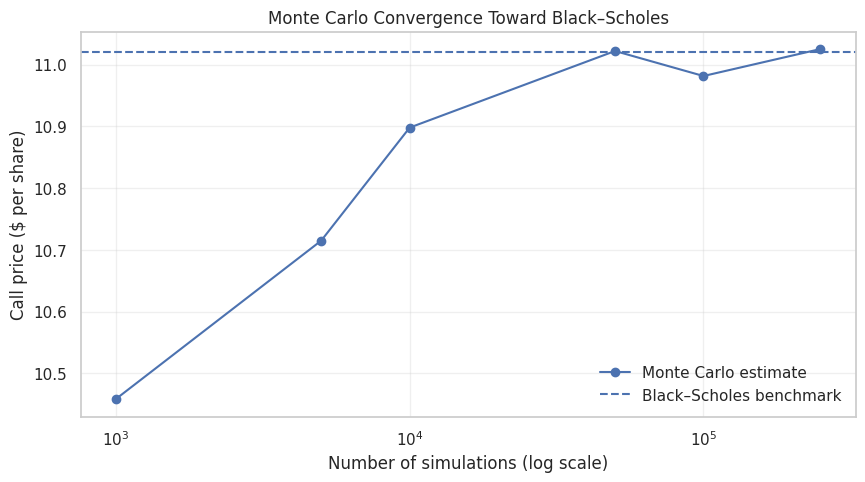

In [33]:
plt.figure(figsize=(10, 5))

plt.plot(
    convergence_results["Simulations"],
    convergence_results["MC Price"],
    marker="o",
    label="Monte Carlo estimate"
)

plt.axhline(
    y=call_bs,
    linestyle="--",
    label="Black–Scholes benchmark"
)

plt.xscale("log")
plt.xlabel("Number of simulations (log scale)")
plt.ylabel("Call price ($ per share)")
plt.title("Monte Carlo Convergence Toward Black–Scholes")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#Option Greeks

In [34]:
def black_scholes_greeks(S0, K, T, r, sigma, option_type="call", q=0.0):
    """
    Calculate Black–Scholes Greeks.

    Vega and Rho are returned per 1.00 change in volatility and rate.
    Theta is returned per year.
    """

    d1, d2 = calculate_d1_d2(S0, K, T, r, sigma, q)

    # Standard normal density at d1.
    pdf_d1 = norm.pdf(d1)

    # Discount factors for the underlying and strike.
    spot_discount = np.exp(-q * T)
    strike_discount = np.exp(-r * T)

    # Gamma and Vega are the same for calls and puts.
    gamma = (
        spot_discount * pdf_d1
        / (S0 * sigma * np.sqrt(T))
    )

    vega = S0 * spot_discount * pdf_d1 * np.sqrt(T)

    if option_type.lower() == "call":
        delta = spot_discount * norm.cdf(d1)

        theta = (
            -S0 * spot_discount * pdf_d1 * sigma
            / (2 * np.sqrt(T))
            + q * S0 * spot_discount * norm.cdf(d1)
            - r * K * strike_discount * norm.cdf(d2)
        )

        rho = K * T * strike_discount * norm.cdf(d2)

    elif option_type.lower() == "put":
        delta = spot_discount * (norm.cdf(d1) - 1)

        theta = (
            -S0 * spot_discount * pdf_d1 * sigma
            / (2 * np.sqrt(T))
            - q * S0 * spot_discount * norm.cdf(-d1)
            + r * K * strike_discount * norm.cdf(-d2)
        )

        rho = -K * T * strike_discount * norm.cdf(-d2)

    else:
        raise ValueError("option_type must be 'call' or 'put'.")

    return {
        "Delta": float(delta),
        "Gamma": float(gamma),
        "Vega (per 1.00 vol)": float(vega),
        "Vega (per 1 percentage point)": float(vega / 100),
        "Theta (per year)": float(theta),
        "Theta (approx. per day)": float(theta / 365),
        "Rho (per 1.00 rate)": float(rho),
        "Rho (per 1 percentage point)": float(rho / 100)
    }


call_greeks = black_scholes_greeks(
    S0, K, T, r, sigma, option_type="call", q=q
)

put_greeks = black_scholes_greeks(
    S0, K, T, r, sigma, option_type="put", q=q
)

greeks_results = pd.DataFrame({
    "Call": call_greeks,
    "Put": put_greeks
})

greeks_results

,Call,Put
Delta,0.5507,-0.4493
Gamma,0.0164,0.0164
Vega (per 1.00 vol),87.2467,87.2467
Vega (per 1 percentage point),0.8725,0.8725
Theta (per year),-75.7274,-43.0040
Theta (approx. per day),-0.2075,-0.1178
Rho (per 1.00 rate),33.9055,-29.0827
Rho (per 1 percentage point),0.3391,-0.2908


# Validation of Greeks using finite differences

In [35]:
# Small changes used for numerical sensitivity checks.
dS = S0 * 0.001
d_sigma = 0.001
d_r = 0.001

# Approximate Delta using a central difference in the stock price.
price_up = black_scholes_price(
    S0 + dS, K, T, r, sigma, "call", q
)
price_down = black_scholes_price(
    S0 - dS, K, T, r, sigma, "call", q
)
delta_fd = (price_up - price_down) / (2 * dS)

# Approximate Gamma using a second central difference.
gamma_fd = (
    price_up - 2 * call_bs + price_down
) / (dS**2)

# Approximate Vega by changing volatility.
price_vol_up = black_scholes_price(
    S0, K, T, r, sigma + d_sigma, "call", q
)
price_vol_down = black_scholes_price(
    S0, K, T, r, sigma - d_sigma, "call", q
)
vega_fd = (price_vol_up - price_vol_down) / (2 * d_sigma)

# Approximate Rho by changing the risk-free rate.
price_rate_up = black_scholes_price(
    S0, K, T, r + d_r, sigma, "call", q
)
price_rate_down = black_scholes_price(
    S0, K, T, r - d_r, sigma, "call", q
)
rho_fd = (price_rate_up - price_rate_down) / (2 * d_r)

greek_validation = pd.DataFrame({
    "Analytical": [
        call_greeks["Delta"],
        call_greeks["Gamma"],
        call_greeks["Vega (per 1.00 vol)"],
        call_greeks["Rho (per 1.00 rate)"]
    ],
    "Finite Difference": [
        delta_fd,
        gamma_fd,
        vega_fd,
        rho_fd
    ]
}, index=["Delta", "Gamma", "Vega", "Rho"])

greek_validation["Absolute Difference"] = (
    greek_validation["Analytical"]
    - greek_validation["Finite Difference"]
).abs()

greek_validation

,Analytical,Finite Difference,Absolute Difference
Delta,0.5507,0.5507,0.0000
Gamma,0.0164,0.0164,0.0000
Vega,87.2467,87.2466,0.0000
Rho,33.9055,33.9054,0.0000


# Heston Stochastic Volatility Model

In [36]:
def heston_monte_carlo_price(
    S0,
    K,
    T,
    r,
    v0,
    kappa,
    theta,
    xi,
    rho,
    option_type="call",
    q=0.0,
    n_simulations=50_000,
    n_steps=120,
    seed=42
):
    """
    Estimate a European option price using Heston Monte Carlo simulation.

    Variance is kept nonnegative when used in square roots and updates.
    The simulation uses a full-truncation-style Euler discretization.
    """

    # Validate the main contract and simulation inputs.
    if S0 <= 0 or K <= 0 or T <= 0:
        raise ValueError("S0, K, and T must be positive.")

    if v0 < 0 or theta < 0:
        raise ValueError("v0 and theta must be nonnegative.")

    if kappa < 0 or xi < 0:
        raise ValueError("kappa and xi must be nonnegative.")

    if not -1 <= rho <= 1:
        raise ValueError("rho must be between -1 and 1.")

    if n_simulations < 2 or n_steps < 1:
        raise ValueError("Use at least two simulations and one time step.")

    rng = np.random.default_rng(seed)

    # Length of each time step in years.
    dt = T / n_steps

    # Initialize stock prices and instantaneous variances.
    stock = np.full(n_simulations, S0, dtype=float)
    variance = np.full(n_simulations, v0, dtype=float)

    # Generate the correlated shocks one time step at a time.
    for _ in range(n_steps):
        z_stock = rng.standard_normal(n_simulations)
        z_independent = rng.standard_normal(n_simulations)

        # Correlate the variance shock with the stock shock.
        z_variance = (
            rho * z_stock
            + np.sqrt(max(1 - rho**2, 0.0)) * z_independent
        )

        # Truncate variance at zero for calculations that require
        # nonnegative variance.
        variance_positive = np.maximum(variance, 0.0)

        # Update stock price using a log-Euler step.
        stock = stock * np.exp(
            (r - q - 0.5 * variance_positive) * dt
            + np.sqrt(variance_positive * dt) * z_stock
        )

        # Update variance with mean reversion and random shocks.
        variance = (
            variance
            + kappa * (theta - variance_positive) * dt
            + xi * np.sqrt(variance_positive * dt) * z_variance
        )

    # Compute the payoff at expiration.
    if option_type.lower() == "call":
        payoff = np.maximum(stock - K, 0)

    elif option_type.lower() == "put":
        payoff = np.maximum(K - stock, 0)

    else:
        raise ValueError("option_type must be 'call' or 'put'.")

    # Discount the payoff to today's value.
    discounted_payoff = np.exp(-r * T) * payoff

    # Calculate the price estimate and Monte Carlo uncertainty.
    price_estimate = discounted_payoff.mean()
    standard_error = (
        discounted_payoff.std(ddof=1) / np.sqrt(n_simulations)
    )

    return {
        "price": float(price_estimate),
        "standard_error": float(standard_error),
        "confidence_low": float(price_estimate - 1.96 * standard_error),
        "confidence_high": float(price_estimate + 1.96 * standard_error),
        "n_simulations": n_simulations,
        "n_steps": n_steps
    }

In [37]:
# Initial Heston variance from the historical volatility estimate.
v0 = sigma**2

# Illustrative Heston parameters.
kappa = 2.0
theta = sigma**2
xi = 0.5
rho = -0.7

heston_call = heston_monte_carlo_price(
    S0=S0,
    K=K,
    T=T,
    r=r,
    v0=v0,
    kappa=kappa,
    theta=theta,
    xi=xi,
    rho=rho,
    option_type="call",
    q=q,
    n_simulations=50_000,
    n_steps=120,
    seed=42
)

heston_put = heston_monte_carlo_price(
    S0=S0,
    K=K,
    T=T,
    r=r,
    v0=v0,
    kappa=kappa,
    theta=theta,
    xi=xi,
    rho=rho,
    option_type="put",
    q=q,
    n_simulations=50_000,
    n_steps=120,
    seed=43
)

heston_results = pd.DataFrame([
    {"Option": "Call", **heston_call},
    {"Option": "Put", **heston_put}
]).set_index("Option")

heston_results

,price,standard_error,confidence_low,confidence_high,n_simulations,n_steps
Option,,,,,,
Call,10.7060,0.0530,10.6022,10.8099,50000,120
Put,7.8845,0.0710,7.7454,8.0237,50000,120


#Compare the pricing models

In [38]:
model_comparison = pd.DataFrame([
    {
        "Option": "Call",
        "Black-Scholes": call_bs,
        "GBM Monte Carlo": mc_call["price"],
        "Heston Monte Carlo": heston_call["price"],
        "GBM MC Standard Error": mc_call["standard_error"],
        "Heston MC Standard Error": heston_call["standard_error"]
    },
    {
        "Option": "Put",
        "Black-Scholes": put_bs,
        "GBM Monte Carlo": mc_put["price"],
        "Heston Monte Carlo": heston_put["price"],
        "GBM MC Standard Error": mc_put["standard_error"],
        "Heston MC Standard Error": heston_put["standard_error"]
    }
]).set_index("Option")

model_comparison

,Black-Scholes,GBM Monte Carlo,Heston Monte Carlo,GBM MC Standard Error,Heston MC Standard Error
Option,,,,,
Call,11.0207,10.9815,10.7060,0.0484,0.0530
Put,8.3264,8.3395,7.8845,0.0407,0.0710


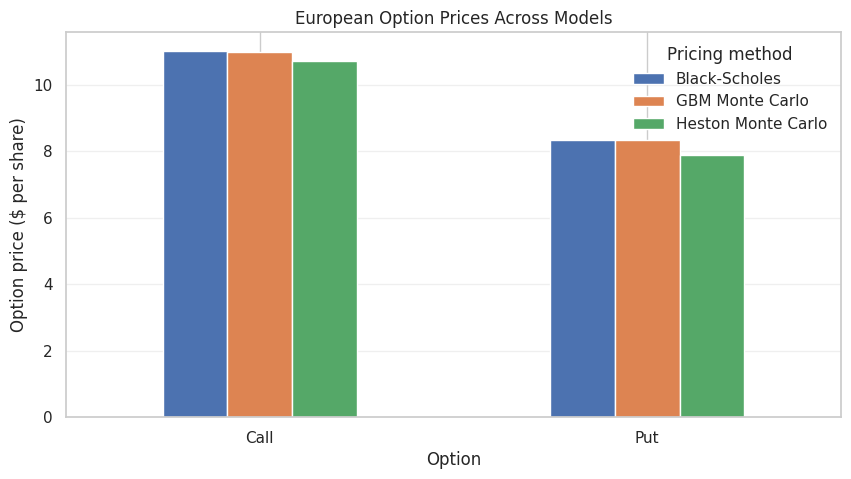

In [39]:
price_columns = [
    "Black-Scholes",
    "GBM Monte Carlo",
    "Heston Monte Carlo"
]

model_comparison[price_columns].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.ylabel("Option price ($ per share)")
plt.title("European Option Prices Across Models")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Pricing method")
plt.show()

#Heston Special- validation

In [40]:
heston_constant_vol_call = heston_monte_carlo_price(
    S0=S0,
    K=K,
    T=T,
    r=r,
    v0=sigma**2,
    kappa=kappa,
    theta=sigma**2,
    xi=0.0,             # No random variance shocks
    rho=rho,
    option_type="call",
    q=q,
    n_simulations=100_000,
    n_steps=120,
    seed=42
)

heston_special_case_check = pd.DataFrame([{
    "Black-Scholes Call": call_bs,
    "Heston with xi=0": heston_constant_vol_call["price"],
    "Absolute Difference": abs(
        call_bs - heston_constant_vol_call["price"]
    ),
    "Heston Standard Error": heston_constant_vol_call["standard_error"],
    "Heston 95% CI Lower": heston_constant_vol_call["confidence_low"],
    "Heston 95% CI Upper": heston_constant_vol_call["confidence_high"],
    "BS Inside Heston CI": (
        heston_constant_vol_call["confidence_low"]
        <= call_bs
        <= heston_constant_vol_call["confidence_high"]
    )
}])

heston_special_case_check

,Black-Scholes Call,Heston with xi=0,Absolute Difference,Heston Standard Error,Heston 95% CI Lower,Heston 95% CI Upper,BS Inside Heston CI
0,11.0207,11.0572,0.0365,0.0482,10.9628,11.1517,True


# Automated Pricing Checks

The final checks evaluate several important properties of the pricing engine:

1. Call and put prices should be nonnegative.
2. Put–call parity should hold for the Black–Scholes prices.
3. Monte Carlo estimates should be consistent with the Black–Scholes benchmark
   within reasonable sampling uncertainty.
4. The Heston constant-variance special case should be consistent with
   Black–Scholes within simulation error.
5. The calculated Greeks should be finite numerical values.

These checks are useful for detecting implementation errors. They do not
establish that the chosen market inputs or model assumptions are correct.

In [41]:
# Check that all theoretical option prices are nonnegative.
assert call_bs >= 0, "Black–Scholes call price must be nonnegative."
assert put_bs >= 0, "Black–Scholes put price must be nonnegative."

assert mc_call["price"] >= 0, "Monte Carlo call price must be nonnegative."
assert mc_put["price"] >= 0, "Monte Carlo put price must be nonnegative."

assert heston_call["price"] >= 0, "Heston call price must be nonnegative."
assert heston_put["price"] >= 0, "Heston put price must be nonnegative."

# Check put–call parity.
assert np.isclose(
    call_bs - put_bs,
    S0 * np.exp(-q * T) - K * np.exp(-r * T),
    atol=1e-8
), "Put–call parity check failed."

# Check that all calculated Greeks are finite.
for greek_name, greek_value in call_greeks.items():
    assert np.isfinite(greek_value), (
        f"Call Greek {greek_name} is not finite."
    )

for greek_name, greek_value in put_greeks.items():
    assert np.isfinite(greek_value), (
        f"Put Greek {greek_name} is not finite."
    )

# Check whether the Black–Scholes prices fall within the MC intervals.
# This is a diagnostic, not an unconditional pass/fail requirement:
# a valid 95% interval can occasionally miss the benchmark.
mc_call_contains_bs = (
    mc_call["confidence_low"] <= call_bs <= mc_call["confidence_high"]
)

mc_put_contains_bs = (
    mc_put["confidence_low"] <= put_bs <= mc_put["confidence_high"]
)

heston_special_case_contains_bs = (
    heston_constant_vol_call["confidence_low"]
    <= call_bs
    <= heston_constant_vol_call["confidence_high"]
)

print("Core pricing checks passed.")
print(f"Call Black–Scholes inside MC interval: {mc_call_contains_bs}")
print(f"Put Black–Scholes inside MC interval: {mc_put_contains_bs}")
print(
    "Black–Scholes inside constant-variance Heston interval: "
    f"{heston_special_case_contains_bs}"
)

Core pricing checks passed.
Call Black–Scholes inside MC interval: True
Put Black–Scholes inside MC interval: True
Black–Scholes inside constant-variance Heston interval: True


# Summary

In [42]:
project_summary = pd.DataFrame([
    {
        "Item": "Underlying",
        "Value": SPY_TICKER
    },
    {
        "Item": "Spot price",
        "Value": S0
    },
    {
        "Item": "Strike price",
        "Value": K
    },
    {
        "Item": "Time to maturity (years)",
        "Value": T
    },
    {
        "Item": "Risk-free rate",
        "Value": r
    },
    {
        "Item": "Historical volatility",
        "Value": sigma
    },
    {
        "Item": "Dividend yield assumption",
        "Value": q
    },
    {
        "Item": "Black–Scholes call price",
        "Value": call_bs
    },
    {
        "Item": "Monte Carlo call price",
        "Value": mc_call["price"]
    },
    {
        "Item": "Heston Monte Carlo call price",
        "Value": heston_call["price"]
    },
    {
        "Item": "Black–Scholes put price",
        "Value": put_bs
    },
    {
        "Item": "Monte Carlo put price",
        "Value": mc_put["price"]
    },
    {
        "Item": "Heston Monte Carlo put price",
        "Value": heston_put["price"]
    }
])

project_summary

,Item,Value
0,Underlying,SPY
1,Spot price,769.0500
2,Strike price,769.0500
3,Time to maturity (years),0.0822
4,Risk-free rate,0.0427
5,Historical volatility,0.1095
6,Dividend yield assumption,0.0000
7,Black–Scholes call price,11.0207
8,Monte Carlo call price,10.9815
9,Heston Monte Carlo call price,10.7060
